# Fundamentals of Machine Learning — Exercise 8

## Dimensionality Reduction and Latent Spaces

Real datasets often contain many correlated or redundant features. Dimensionality reduction creates a smaller representation that may help us:

- visualise high-dimensional data,
- compress information,
- remove some redundancy or noise,
- prepare features for another model,
- inspect latent structure.

This exercise compares four important approaches:

- **Principal Component Analysis (PCA)**,
- **Truncated Singular Value Decomposition (SVD)**,
- **t-distributed Stochastic Neighbour Embedding (t-SNE)**,
- **Uniform Manifold Approximation and Projection (UMAP)**.

The classroom workflow remains:

> **question → prediction → computation → visualisation → interpretation → verification**

### Learning outcomes

After completing this exercise, you should be able to:

- explain what a principal component represents,
- distinguish explained variance from reconstruction quality,
- explain why scaling can change PCA,
- select a defensible number of principal components,
- reconstruct data from a lower-dimensional PCA representation,
- explain when TruncatedSVD is useful for sparse data,
- distinguish compression methods from visualisation methods,
- compare PCA, t-SNE, and UMAP cautiously,
- explain why distances and cluster sizes in t-SNE plots can be misleading,
- use local-neighbourhood evidence to audit an embedding,
- fit dimensionality reduction inside a leakage-safe modelling pipeline,
- use AI to question an interpretation after producing your own answer.

**Recommended duration:** 100–120 minutes.  
The final latent-space audit may be completed as homework.

## How to work in this exercise

Most code is already prepared. Your task is to:

1. **predict** before running a result,
2. **change** only clearly marked settings,
3. **connect** plots to a mathematical or geometric idea,
4. **compare** alternative representations,
5. **state** what cannot be concluded from a visualisation,
6. **verify** at least one visual claim numerically or in the original feature space.

A beautiful two-dimensional plot is not automatically a faithful map of the original data.

## 0. Imports

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits, load_wine
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE, trustworthiness
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## Reading: Mathematical foundations of PCA

Principal Component Analysis (PCA) is a technique for reducing the number of features in a dataset while preserving as much information as possible.

The main idea is to find **new directions in the data along which the observations vary the most**.

To understand PCA, we first need four mathematical concepts:

1. Covariance matrix
2. Eigenvalues and eigenvectors
3. Projection
4. Reconstruction

### 1. Covariance matrix

Suppose our dataset contains $n$ observations and $d$ numerical features. We represent it as a matrix:

$$
X \in \mathbb{R}^{n \times d}
$$

Before applying PCA, we center each feature by subtracting its mean:

$$
X_c = X - \mu
$$

where $\mu$ is the vector of feature means, subtracted from every observation.

The **covariance matrix** describes how individual features vary and how they vary together.

$$
C = \frac{1}{n-1}X_c^T X_c
$$

For a dataset with two features, the covariance matrix is:

$$
C =
\begin{bmatrix}
\operatorname{Var}(x_1) & \operatorname{Cov}(x_1,x_2) \\
\operatorname{Cov}(x_2,x_1) & \operatorname{Var}(x_2)
\end{bmatrix}
$$

The matrix contains two types of information:

- **Diagonal elements:** Variance of each feature. They describe how much individual features vary.
- **Off-diagonal elements:** Covariance between pairs of features. They describe whether two features tend to increase or decrease together.

For example:

$$
C =
\begin{bmatrix}
4 & 3 \\
3 & 4
\end{bmatrix}
$$

This tells us that:

- Both features have variance $4$.
- Their covariance is $3$, indicating a strong positive linear relationship.
- The observations tend to form an elongated cloud along a diagonal direction.

The covariance matrix is always symmetric, meaning:

$$
\operatorname{Cov}(x_i,x_j)=\operatorname{Cov}(x_j,x_i)
$$

**Important:** Covariance depends on the scale of the features. This is one reason why feature scaling can significantly affect PCA.

### 2. Eigenvectors and eigenvalues

The covariance matrix describes variability along the original coordinate axes. However, the direction of maximum variability may be different from these axes.

We want to find new directions that better describe the shape of the data.

These directions can be found using **eigenvectors and eigenvalues** of the covariance matrix.

An eigenvector $\mathbf{v}$ satisfies:

$$
C\mathbf{v}=\lambda\mathbf{v}
$$

where:

- $C$ is the covariance matrix.
- $\mathbf{v}$ is an eigenvector.
- $\lambda$ is the corresponding eigenvalue.

An eigenvector is a direction that remains unchanged when transformed by $C$, except for its magnitude.

For PCA, this has a particularly useful interpretation:

- **Eigenvectors** define the directions of the principal components.
- **Eigenvalues** describe how much variance is captured along these directions, assuming unit-length eigenvectors.

For our previous example:

$$
C =
\begin{bmatrix}
4 & 3 \\
3 & 4
\end{bmatrix}
$$

the eigenvalues are:

$$
\lambda_1=7,\qquad \lambda_2=1
$$

The corresponding normalized eigenvectors are:

$$
\mathbf{v}_1 =
\frac{1}{\sqrt{2}}
\begin{bmatrix}1\\1\end{bmatrix},
\qquad
\mathbf{v}_2 =
\frac{1}{\sqrt{2}}
\begin{bmatrix}1\\-1\end{bmatrix}
$$

The first eigenvector points along the diagonal where both features increase together.

The second eigenvector points along the perpendicular diagonal.

Because $\lambda_1 > \lambda_2$, the first direction captures more variance.

The proportion of total variance explained by the first principal component is:

$$
\frac{\lambda_1}{\lambda_1+\lambda_2}
=
\frac{7}{8}
=
87.5\%
$$

Therefore, by keeping only the first principal component, we preserve **87.5% of the total variance**, even though we reduce the dataset from two dimensions to one.

### 3. Projection onto principal components

Once we have identified the principal components, we can represent observations using the new coordinate system.

This operation is called **projection**.

Suppose we want to reduce our dataset from $d$ dimensions to $k$ dimensions, where $k < d$.

We select the $k$ eigenvectors associated with the largest eigenvalues and arrange them into a matrix:

$$
W_k =
\begin{bmatrix}
\mathbf{v}_1 & \mathbf{v}_2 & \cdots & \mathbf{v}_k
\end{bmatrix}
$$

The transformed dataset is:

$$
Z = X_c W_k
$$

where:

- $X_c$ is the centered original dataset of shape $(n,d)$.
- $W_k$ contains the selected principal components and has shape $(d,k)$.
- $Z$ is the projected dataset of shape $(n,k)$.

**Geometrical interpretation:**

Imagine a two-dimensional cloud of points forming an elongated ellipse.

The first principal component follows the longest direction of the ellipse.

If we keep only this component, every point is orthogonally projected onto a line passing through the center of the cloud.

Instead of describing each observation using two coordinates $(x_1,x_2)$, we now describe it using a single coordinate along this line.

We have reduced the dimensionality from 2D to 1D.

### 4. Reconstruction from principal components

Can we transform the reduced data back into the original feature space?

Yes. This operation is called **reconstruction**.

We use the projected data and the principal component directions:

$$
\hat{X} = ZW_k^T+\mu
$$

where $\hat{X}$ is the reconstructed dataset.

However, if we discarded some principal components, the reconstruction is generally not exact.

The difference between the original and reconstructed observations is called the **reconstruction error**.

For one observation:

$$
e_i = \|\mathbf{x}_i-\hat{\mathbf{x}}_i\|^2
$$

A common measure across the entire dataset is the mean squared reconstruction error:

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}\|\mathbf{x}_i-\hat{\mathbf{x}}_i\|^2
$$

Geometrically, reconstruction takes a projected point on the principal component line and maps it back into the original two-dimensional space.

The reconstructed point lies on that line, so information about its original position perpendicular to the line has been lost.

Keeping more principal components generally decreases the reconstruction error.

If we keep all principal components, reconstruction is exact up to numerical precision.

### 5. How everything connects

PCA follows a sequence of mathematical operations:

1. **Center the data** so that every feature has zero mean.
2. **Compute the covariance matrix** to describe variability and relationships between features.
3. **Find eigenvectors and eigenvalues** to identify directions of variability and quantify the variance along them.
4. **Select the principal components** associated with the largest eigenvalues.
5. **Project the observations** into the lower-dimensional space.
6. **Reconstruct the observations**, if needed, to evaluate how much information was lost.

The central trade-off is:

**Fewer dimensions → simpler representation, but potentially greater information loss.**

PCA chooses the directions that maximize preserved variance and, equivalently, minimize squared reconstruction error among all linear orthogonal projections of the same dimensionality.

> **Remember:** PCA does not select the most important original features. It constructs new features as linear combinations of the original ones. These new features are called *principal components*.

## 1. PCA begins with a direction of maximum variance

Consider a two-dimensional dataset whose features are strongly correlated.

Before running the cell, predict:

1. In which direction does the cloud vary most?
2. Would a horizontal or vertical one-dimensional projection preserve the data well?
3. What direction would you choose if only one coordinate could be retained?

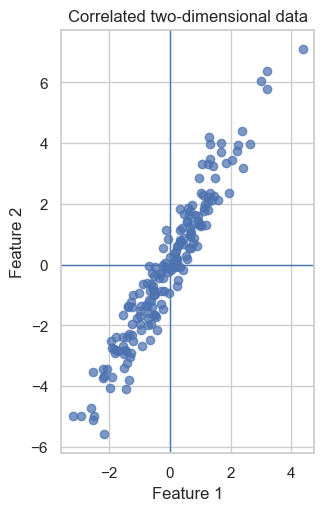

In [7]:
rng = np.random.default_rng(RANDOM_STATE)

x1 = rng.normal(0, 1.5, 180)
x2 = 1.8 * x1 + rng.normal(0, 0.65, 180)
X_geometry = np.column_stack([x1, x2])

plt.figure(figsize=(7, 5.5))
plt.scatter(X_geometry[:, 0], X_geometry[:, 1], alpha=0.72)
plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)
plt.gca().set_aspect('equal', adjustable='box')
plt.title('Correlated two-dimensional data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

### Compute the principal directions from the covariance matrix

For centred data, PCA finds eigenvectors of the covariance matrix.

- The first eigenvector points in the direction of maximum variance.
- The second eigenvector is orthogonal to the first.
- Eigenvalues quantify variance along those directions.

In [8]:
X_centered = X_geometry - X_geometry.mean(axis=0)
covariance_matrix = np.cov(X_centered, rowvar=False)

eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

manual_variance_ratio = eigenvalues / eigenvalues.sum()

print('Covariance matrix:')
display(pd.DataFrame(covariance_matrix, index=['Feature 1', 'Feature 2'], columns=['Feature 1', 'Feature 2']).round(3))

print('Explained variance ratio:')
display(pd.Series(manual_variance_ratio, index=['PC1', 'PC2']).round(3))

Covariance matrix:


,Feature 1,Feature 2
Feature 1,1.693,2.989
Feature 2,2.989,5.714


Explained variance ratio:


PC1    0.986
PC2    0.014
dtype: float64

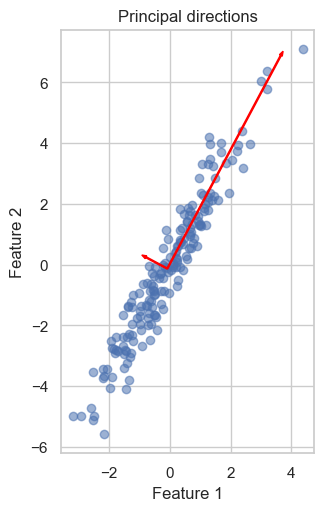

In [11]:
mean_point = X_geometry.mean(axis=0)
scale = 3.0

plt.figure(figsize=(7, 5.5))
plt.scatter(X_geometry[:, 0], X_geometry[:, 1], alpha=0.55)

for component_index in range(2):
    direction = eigenvectors[:, component_index]
    length = scale * np.sqrt(eigenvalues[component_index])
    plt.arrow(
        mean_point[0],
        mean_point[1],
        direction[0] * length,
        direction[1] * length,
        width=0.035,
        color='red',
        length_includes_head=True,
        label=f'PC{component_index + 1}',
    )

plt.gca().set_aspect('equal', adjustable='box')
plt.title('Principal directions')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

### Activity 1 - Interpret the geometry

Complete the explanation:

> PC1 points approximately __________ because __________.
>
> PC1 preserves about __________ of the total variance.
>
> Reducing the dataset to one component loses mainly __________.

Why can the sign of a principal component be reversed without changing the solution?

### Project to one dimension and reconstruct

PCA compression has two steps:

1. project observations onto the selected component,
2. reconstruct an approximation in the original feature space.

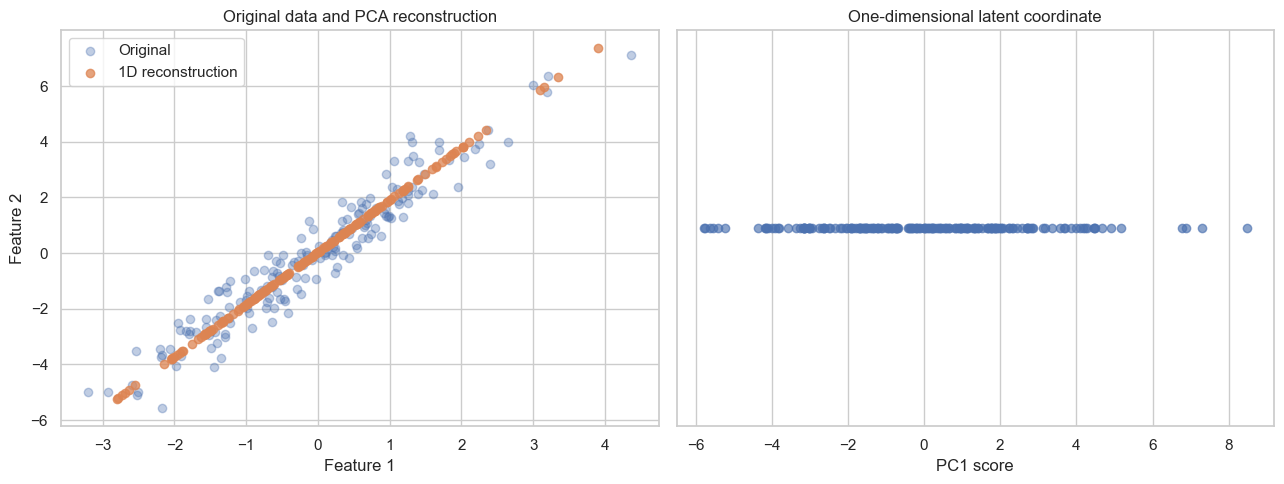

Reconstruction MSE: 0.0500


In [10]:
pca_one = PCA(n_components=1)
X_one_dimensional = pca_one.fit_transform(X_geometry)
X_reconstructed = pca_one.inverse_transform(X_one_dimensional)

reconstruction_mse = np.mean((X_geometry - X_reconstructed) ** 2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X_geometry[:, 0], X_geometry[:, 1], alpha=0.35, label='Original')
axes[0].scatter(X_reconstructed[:, 0], X_reconstructed[:, 1], alpha=0.75, label='1D reconstruction')
axes[0].set_title('Original data and PCA reconstruction')
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')
axes[0].legend()

axes[1].scatter(X_one_dimensional[:, 0], np.zeros(len(X_one_dimensional)), alpha=0.65)
axes[1].set_title('One-dimensional latent coordinate')
axes[1].set_xlabel('PC1 score')
axes[1].set_yticks([])

plt.tight_layout()
plt.show()

print(f'Reconstruction MSE: {reconstruction_mse:.4f}')

### Verification checkpoint

Compare the original and reconstructed points.

- Which direction of variation was removed?
- Does high explained variance mean perfect reconstruction?
- What would happen if the original cloud were approximately circular?

## 2. Scaling can change the meaning of PCA

The Wine dataset contains chemical measurements with very different units and numerical ranges.

Before running PCA, predict:

1. Which feature is likely to dominate PCA without scaling?
2. Does a large numerical variance automatically mean that a feature is scientifically more important?
3. What question does standardisation change?

In [12]:
wine = load_wine(as_frame=True)
X_wine = wine.data.copy()
y_wine = wine.target.copy()

wine_scale_table = X_wine.agg(['mean', 'std', 'min', 'max']).T
wine_scale_table['range'] = wine_scale_table['max'] - wine_scale_table['min']
display(wine_scale_table.sort_values('std', ascending=False).round(2))

,mean,std,min,max,range
proline,746.89,314.91,278.00,1680.00,1402.00
magnesium,99.74,14.28,70.00,162.00,92.00
alcalinity_of_ash,19.49,3.34,10.60,30.00,19.40
color_intensity,5.06,2.32,1.28,13.00,11.72
malic_acid,2.34,1.12,0.74,5.80,5.06
flavanoids,2.03,1.00,0.34,5.08,4.74
alcohol,13.00,0.81,11.03,14.83,3.80
od280/od315_of_diluted_wines,2.61,0.71,1.27,4.00,2.73
total_phenols,2.30,0.63,0.98,3.88,2.90
proanthocyanins,1.59,0.57,0.41,3.58,3.17


In [13]:
pca_raw = PCA(n_components=2)
X_wine_raw_pca = pca_raw.fit_transform(X_wine)

wine_scaler = StandardScaler()
X_wine_scaled = wine_scaler.fit_transform(X_wine)

pca_scaled = PCA(n_components=2)
X_wine_scaled_pca = pca_scaled.fit_transform(X_wine_scaled)

raw_loadings = pd.Series(
    np.abs(pca_raw.components_[0]),
    index=X_wine.columns,
    name='absolute PC1 loading — raw',
).sort_values(ascending=False)

scaled_loadings = pd.Series(
    np.abs(pca_scaled.components_[0]),
    index=X_wine.columns,
    name='absolute PC1 loading — scaled',
).sort_values(ascending=False)

comparison_loadings = pd.concat([raw_loadings, scaled_loadings], axis=1)
display(comparison_loadings.head(8).round(3))

,absolute PC1 loading — raw,absolute PC1 loading — scaled
proline,1.000,0.287
magnesium,0.018,0.142
alcalinity_of_ash,0.005,0.239
color_intensity,0.002,0.089
alcohol,0.002,0.144
flavanoids,0.002,0.423
total_phenols,0.001,0.395
od280/od315_of_diluted_wines,0.001,0.376


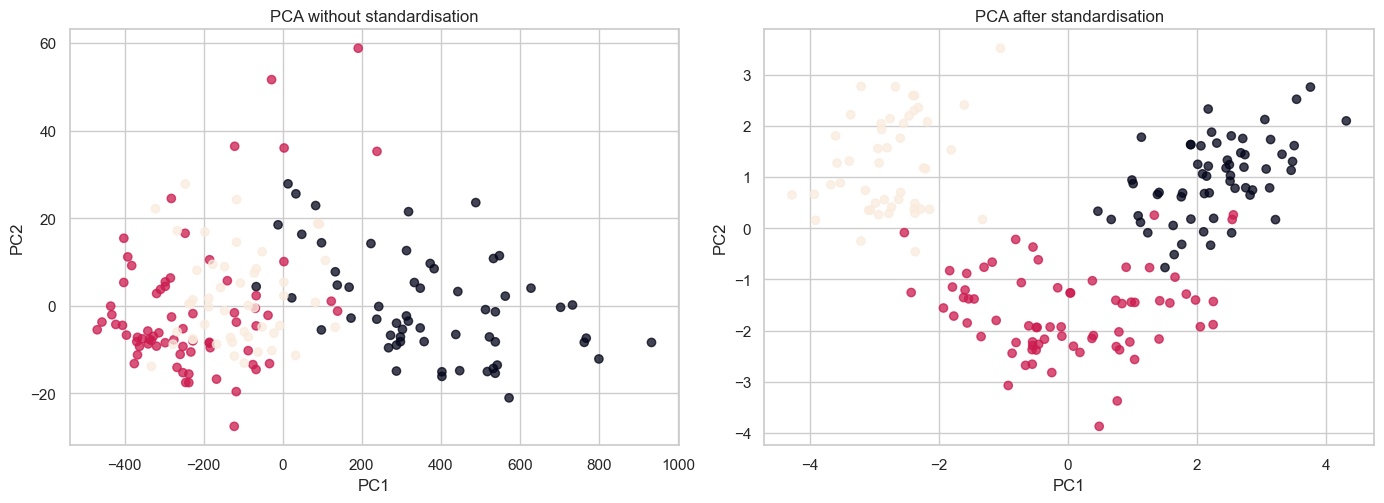

Explained variance, raw: [0.998 0.002]
Explained variance, scaled: [0.362 0.192]


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

axes[0].scatter(X_wine_raw_pca[:, 0], X_wine_raw_pca[:, 1], c=y_wine, alpha=0.75)
axes[0].set_title('PCA without standardisation')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

axes[1].scatter(X_wine_scaled_pca[:, 0], X_wine_scaled_pca[:, 1], c=y_wine, alpha=0.75)
axes[1].set_title('PCA after standardisation')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()

print('Explained variance, raw:', np.round(pca_raw.explained_variance_ratio_, 3))
print('Explained variance, scaled:', np.round(pca_scaled.explained_variance_ratio_, 3))

### Activity 2 - Explain what scaling changed

1. Which feature dominated raw PC1?
2. Why did this happen?
3. What does standardised PCA consider equally before learning the components?
4. Is standardisation always mandatory? State one situation in which original units may be meaningful.

## 3. How many principal components should we keep?

We now use handwritten digit images.

Each 8×8 image becomes a vector of 64 pixel intensities. PCA can compress those 64 features into fewer latent coordinates.

Observations: 1797
Original features: 64
Image shape: (8, 8)


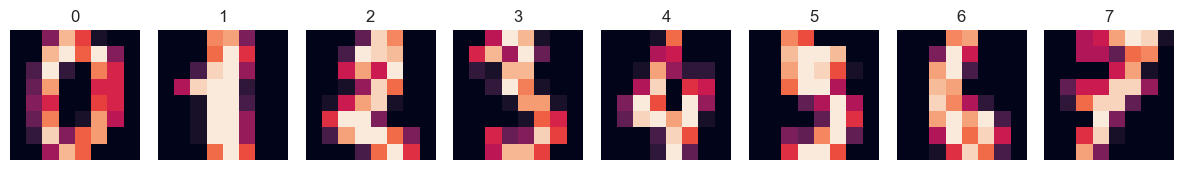

In [15]:
digits = load_digits()
X_digits = digits.data
y_digits = digits.target
images_digits = digits.images

print('Observations:', X_digits.shape[0])
print('Original features:', X_digits.shape[1])
print('Image shape:', images_digits.shape[1:])

fig, axes = plt.subplots(1, 8, figsize=(12, 2.2))
for axis, image, label in zip(axes, images_digits[:8], y_digits[:8]):
    axis.imshow(image)
    axis.set_title(str(label))
    axis.axis('off')
plt.tight_layout()
plt.show()

### Predict before viewing the curve

How many components do you expect to need for:

- approximately 80% of the variance?
- approximately 90%?
- approximately 95%?

Do you expect 95% explained variance to require 95% of the original 64 features? Why or why not?

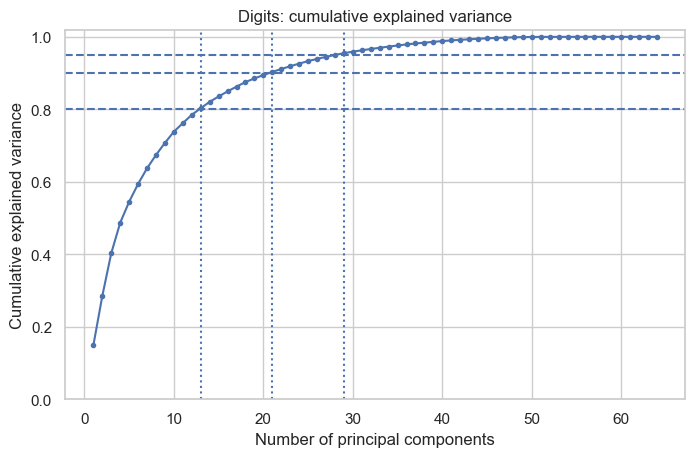

,minimum components
variance threshold,
0.80,13
0.90,21
0.95,29


In [16]:
pca_digits_full = PCA()
X_digits_pca_full = pca_digits_full.fit_transform(X_digits)

cumulative_variance = np.cumsum(pca_digits_full.explained_variance_ratio_)
thresholds = [0.80, 0.90, 0.95]
components_for_threshold = {
    threshold: int(np.argmax(cumulative_variance >= threshold) + 1)
    for threshold in thresholds
}

plt.figure(figsize=(8, 4.8))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', markersize=3)
for threshold in thresholds:
    plt.axhline(threshold, linestyle='--')
    plt.axvline(components_for_threshold[threshold], linestyle=':')
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative explained variance')
plt.title('Digits: cumulative explained variance')
plt.ylim(0, 1.02)
plt.show()

pd.Series(
    components_for_threshold,
    name='minimum components',
).rename_axis('variance threshold').to_frame()

### Activity 3 - Choose a dimensionality for a stated purpose

Complete the recommendations:

> For strong compression with visible information loss, I would test approximately __________ components.
>
> For retaining at least 90% of the variance, I need __________ components.
>
> I would not choose the number only from the curve because __________.

Why is explained variance a property of the features, not a direct measure of classification accuracy?

### Reconstruct digits from different latent dimensions

Change `COMPONENT_COUNTS` only after viewing the first result.

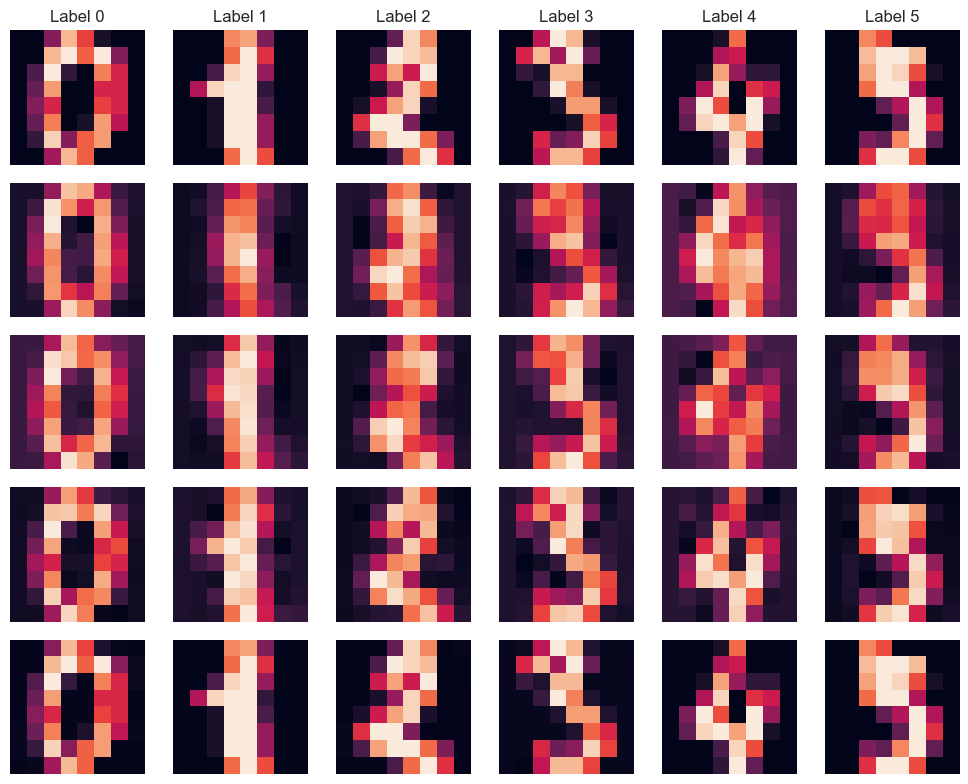

,components,explained variance,reconstruction MSE
0,5,0.545,8.542
1,15,0.835,3.092
2,30,0.959,0.768
3,50,1.000,0.009


In [17]:
COMPONENT_COUNTS = [5, 15, 30, 50]
SAMPLE_INDICES = [0, 1, 2, 3, 4, 5]

fig, axes = plt.subplots(
    len(COMPONENT_COUNTS) + 1,
    len(SAMPLE_INDICES),
    figsize=(10, 8),
)

for column, sample_index in enumerate(SAMPLE_INDICES):
    axes[0, column].imshow(images_digits[sample_index])
    axes[0, column].set_title(f'Label {y_digits[sample_index]}')
    axes[0, column].axis('off')

axes[0, 0].set_ylabel('Original')

reconstruction_rows = []

for row, component_count in enumerate(COMPONENT_COUNTS, start=1):
    pca_model = PCA(n_components=component_count)
    transformed = pca_model.fit_transform(X_digits)
    reconstructed = pca_model.inverse_transform(transformed)

    mse = np.mean((X_digits - reconstructed) ** 2)
    reconstruction_rows.append({
        'components': component_count,
        'explained variance': pca_model.explained_variance_ratio_.sum(),
        'reconstruction MSE': mse,
    })

    for column, sample_index in enumerate(SAMPLE_INDICES):
        axes[row, column].imshow(reconstructed[sample_index].reshape(8, 8))
        axes[row, column].axis('off')

    axes[row, 0].set_ylabel(f'{component_count} PCs')

plt.tight_layout()
plt.show()

pd.DataFrame(reconstruction_rows).round(3)

### Activity 4 - Connect numbers to visible information

1. At what component count do the digit identities become reliably recognisable?
2. Which details disappear first?
3. Does the reconstruction MSE decrease monotonically? Why?
4. Could a classifier still work well on a reconstruction that looks imperfect to a human?

## Reading: Singular Value Decomposition (SVD)

In the previous sections, we used **Principal Component Analysis (PCA)** to reduce dimensionality by finding directions of maximum variance.

Now we will introduce another mathematical technique: **Singular Value Decomposition (SVD)**.

SVD is closely related to PCA, but it can be applied to any real-valued matrix, including rectangular matrices.

It is particularly useful when working with **high-dimensional sparse data**, such as text represented by word frequencies.

### 1. What is Singular Value Decomposition?

Suppose we have a data matrix:

$$
X \in \mathbb{R}^{n \times d}
$$

where:

- $n$ is the number of observations,
- $d$ is the number of features.

SVD decomposes this matrix into three matrices:

$$
\boxed{X = U \Sigma V^T}
$$

Using the reduced (thin) form of SVD, assuming $r=\operatorname{rank}(X)$:

- $U \in \mathbb{R}^{n \times r}$ contains the **left singular vectors**.
- $\Sigma \in \mathbb{R}^{r \times r}$ is a diagonal matrix containing the **singular values**.
- $V^T \in \mathbb{R}^{r \times d}$ contains the transposed **right singular vectors**.

The singular values are non-negative and conventionally sorted:

$$
\sigma_1 \geq \sigma_2 \geq \cdots \geq \sigma_r > 0
$$

Intuitively:

- **$V$:** Defines important directions in the original feature space.
- **$\Sigma$:** Describes how strongly each direction contributes to the matrix.
- **$U$:** Describes the corresponding patterns across observations.

The original matrix can also be written as a sum:

$$
X = \sum_{i=1}^{r} \sigma_i \mathbf{u}_i \mathbf{v}_i^T
$$

Each term represents one rank-one contribution to the original data.

### 2. How is SVD related to eigenvectors and PCA?

Recall that PCA finds eigenvectors and eigenvalues of the covariance matrix.

For centered data:

$$
C = \frac{1}{n-1}X_c^T X_c
$$

Now suppose we compute SVD of the centered data:

$$
X_c = U\Sigma V^T
$$

Substituting this into the covariance matrix gives:

$$
C = \frac{1}{n-1}V\Sigma^2V^T
$$

This reveals an important relationship:

- The **right singular vectors** of centered data are the principal component directions.
- The **squared singular values**, divided by $n-1$, are the eigenvalues of the covariance matrix.

$$
\lambda_i = \frac{\sigma_i^2}{n-1}
$$

Therefore, PCA can be computed using SVD without explicitly constructing the covariance matrix.

**Important distinction:** PCA applies this decomposition to centered data. Applying SVD directly to an uncentered matrix generally produces different directions.

### 3. Truncated SVD: Keeping only the important components

Just as PCA can keep only the first $k$ principal components, SVD can retain only the first $k$ singular values and their corresponding vectors.

This is called **Truncated SVD**.

$$
X_k = U_k \Sigma_k V_k^T
$$

where $k < r$.

Instead of using all $d$ original features, we represent each observation using $k$ coordinates:

$$
Z = XV_k = U_k\Sigma_k
$$

The reduced representation has shape:

$$
Z \in \mathbb{R}^{n \times k}
$$

The approximation $X_k$ is the best rank-$k$ approximation to $X$ in terms of squared Frobenius reconstruction error.

This means that among all matrices of rank at most $k$, it minimizes:

$$
\|X-X_k\|_F^2
$$

Keeping more components reduces this approximation error.

### 4. Why is TruncatedSVD useful for text data?

Consider a collection of documents represented using the **Bag-of-Words** model.

Each row represents a document, and each column represents a word.

For example:

| Document | cat | dog | football | goal |
|---|---:|---:|---:|---:|
| Document 1 | 2 | 1 | 0 | 0 |
| Document 2 | 1 | 2 | 0 | 0 |
| Document 3 | 0 | 0 | 2 | 1 |
| Document 4 | 0 | 0 | 1 | 3 |

This is a **document–term matrix**.

In real applications, the vocabulary may contain tens of thousands of words, but each document contains only a small fraction of them.

Most entries are therefore zero. Such a matrix is called **sparse**.

PCA normally centers each feature by subtracting its mean. This can turn many zero entries into nonzero values, destroying sparsity and increasing memory requirements.

`TruncatedSVD` in scikit-learn does not center the input matrix, making it suitable for sparse document–term matrices.

### 5. What do SVD components represent in text data?

Imagine that our dataset contains documents about:

- Animals and pets.
- Football and sports.
- Programming and computers.

The original features are individual words.

However, related words often occur together in similar documents.

SVD can identify patterns of word co-occurrence and represent documents using a smaller number of **latent components**.

For example, a component may assign large weights to words such as:

`football`, `goal`, `match`, `team`

We might interpret this component as being related to sports.

Another component might emphasize:

`cat`, `dog`, `pet`, `animal`

We might interpret it as being related to animals.

This approach is closely related to **Latent Semantic Analysis (LSA)**.

However, an SVD component is not necessarily a clean, independent topic. It is a mathematical direction in the feature space, and its interpretation depends on the data.

Also, component weights can be positive or negative. Their signs are not inherently meaningful because singular vectors can be multiplied by $-1$ without changing the decomposition, provided the corresponding paired vector is also sign-reversed.

### 6. PCA vs. TruncatedSVD

| Property | PCA | TruncatedSVD |
|---|---|---|
| Centers the features | Yes | No |
| Works with dense data | Yes | Yes |
| Suitable for large sparse matrices | Usually less convenient | Yes |
| Finds directions of maximum centered variance | Yes | Not necessarily |
| Supports dimensionality reduction | Yes | Yes |
| Typical application | Numerical datasets | Text and sparse matrices |

**Remember:** PCA and TruncatedSVD are mathematically closely related, but their results generally differ because PCA centers the data while scikit-learn's TruncatedSVD does not.

### 7. How everything connects

We can now connect the methods introduced in this exercise:

1. **Covariance matrix:** Describes the variance of features and their relationships.
2. **Eigenvectors and eigenvalues:** Identify important directions and their variances.
3. **PCA:** Finds directions of maximum variance in centered data.
4. **SVD:** Decomposes a matrix into orthogonal directions and singular values.
5. **TruncatedSVD:** Keeps only the strongest singular components to construct a lower-dimensional representation.

The key idea is that a high-dimensional dataset may contain a smaller number of underlying patterns that explain much of its structure.

> **Remember:** PCA finds directions of maximum variance after centering the data. TruncatedSVD finds a low-rank approximation of the original matrix without requiring centering, which is especially useful for sparse text data.

## 4. TruncatedSVD for sparse text data

PCA centres every feature, which can destroy sparsity. For a document–term matrix with many zeros, **TruncatedSVD** is often more practical because it operates without centring the matrix.

We will create a tiny bag-of-words dataset. The original words are high-dimensional observed features; the SVD components form a lower-dimensional latent representation.

In [18]:
documents = [
    'machine learning model data prediction',
    'classification model training data',
    'clustering features distance algorithm',
    'neural network model optimisation',
    'bread recipe flour yeast baking',
    'vegetable soup recipe cooking kitchen',
    'cake chocolate sugar baking recipe',
    'pasta sauce tomato cooking meal',
    'mountain hiking trail forest route',
    'travel train hotel city trip',
    'camping tent lake outdoor trip',
    'hiking map summit mountain route',
]

document_names = [
    'ML 1', 'ML 2', 'ML 3', 'ML 4',
    'Food 1', 'Food 2', 'Food 3', 'Food 4',
    'Travel 1', 'Travel 2', 'Travel 3', 'Travel 4',
]

vectorizer = CountVectorizer(stop_words='english')
X_text = vectorizer.fit_transform(documents)
terms = np.array(vectorizer.get_feature_names_out())

print('Document–term matrix shape:', X_text.shape)
print('Non-zero proportion:', round(X_text.nnz / (X_text.shape[0] * X_text.shape[1]), 3))

Document–term matrix shape: (12, 46)
Non-zero proportion: 0.103


### Predict the latent structure

How many broad themes do you expect?

Which words should receive strong weights in a component related to:

- machine learning,
- food,
- travel or hiking?

In [19]:
svd_text = TruncatedSVD(n_components=3, random_state=RANDOM_STATE)
X_text_latent = svd_text.fit_transform(X_text)

component_rows = []
for component_index, component in enumerate(svd_text.components_, start=1):
    top_indices = np.argsort(np.abs(component))[::-1][:7]
    component_rows.append({
        'component': f'Component {component_index}',
        'top weighted terms': ', '.join(terms[top_indices]),
        'explained variance ratio': svd_text.explained_variance_ratio_[component_index - 1],
    })

latent_documents = pd.DataFrame(
    X_text_latent,
    index=document_names,
    columns=['Latent 1', 'Latent 2', 'Latent 3'],
)

display(pd.DataFrame(component_rows).round(3))
display(latent_documents.round(3))

,component,top weighted terms,explained variance ratio
0,Component 1,"route, mountain, hiking, forest, trail, summit...",0.133
1,Component 2,"recipe, baking, cooking, bread, yeast, flour, ...",0.110
2,Component 3,"model, data, prediction, machine, learning, tr...",0.109


,Latent 1,Latent 2,Latent 3
ML 1,-0.0,-0.000,1.908
ML 2,0.0,0.000,1.539
ML 3,0.0,0.000,-0.000
ML 4,-0.0,-0.000,1.083
Food 1,0.0,1.687,0.000
Food 2,0.0,1.373,0.000
Food 3,0.0,1.687,0.000
Food 4,0.0,0.488,0.000
Travel 1,2.0,-0.000,0.000
Travel 2,0.0,0.000,-0.000


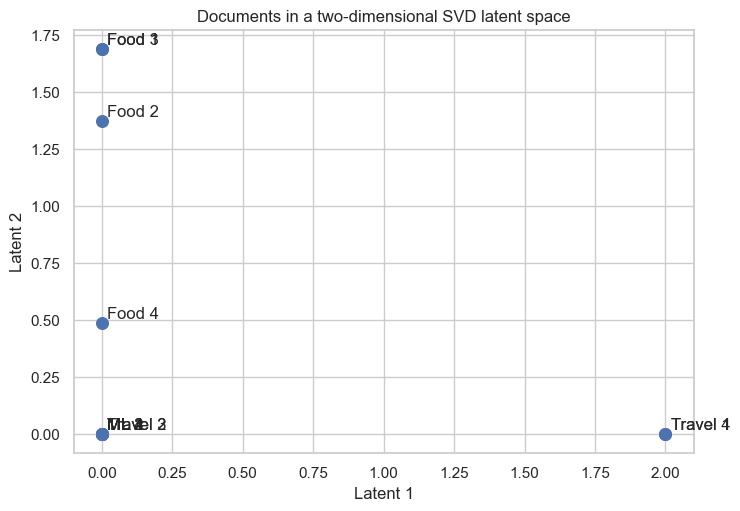

In [20]:
plt.figure(figsize=(8, 5.5))
plt.scatter(latent_documents['Latent 1'], latent_documents['Latent 2'], s=70)

for name, row in latent_documents.iterrows():
    plt.text(row['Latent 1'] + 0.02, row['Latent 2'] + 0.02, name)

plt.title('Documents in a two-dimensional SVD latent space')
plt.xlabel('Latent 1')
plt.ylabel('Latent 2')
plt.show()

### Activity 5 - Interpret a latent component cautiously

Choose one component and complete:

> This component appears related to __________ because the strongly weighted terms include __________.
>
> It should not be called a hard topic label because __________.

Why may the sign of an SVD component change between implementations or runs without changing its underlying axis?

## Reading: t-SNE (t-distributed Stochastic Neighbor Embedding)

**t-SNE** is a nonlinear dimensionality reduction technique primarily used to visualise high-dimensional datasets in two or three dimensions.

Unlike PCA, which finds directions of maximum variance, **t-SNE tries to preserve local neighbourhood relationships between observations**.

### 1. How does t-SNE work?

The main idea is that observations that are similar in the original high-dimensional space should remain close together in the low-dimensional representation.

The algorithm works approximately as follows:

1. Calculate similarities between observations in the original high-dimensional space.
2. Represent these similarities as probabilities, assigning higher probabilities to nearby observations.
3. Place the observations in a low-dimensional space (usually 2D).
4. Iteratively adjust their positions to make the low-dimensional similarities resemble the original ones.

The difference between the two similarity distributions is measured using **Kullback–Leibler divergence (KL divergence)**, which t-SNE attempts to minimise.

### 2. What is perplexity?

One of the most important t-SNE parameters is `perplexity`.

It controls the effective size of the neighbourhood considered when calculating similarities.

- **Low perplexity:** Emphasises very local relationships and may produce many small groups.
- **High perplexity:** Considers broader neighbourhoods and may reveal larger-scale structures.

Typical values range from 5 to 50, although the best choice depends on the dataset.

Perplexity must be smaller than the number of observations.

### 3. How should we interpret a t-SNE plot?

A t-SNE visualisation may show distinct clusters, but we must interpret them carefully.

- **Nearby points:** Usually represent observations that were similar in the original space.
- **Distances between separated clusters:** Do not necessarily reflect their original distances.
- **Cluster sizes and shapes:** May be distorted by the algorithm.
- **Different runs or parameters:** May produce different visualisations.

Importantly, t-SNE does not guarantee that visually separated groups correspond to meaningful classes or natural clusters.

### 4. PCA vs. t-SNE

| PCA | t-SNE |
|---|---|
| Linear transformation | Nonlinear embedding |
| Maximises preserved variance | Focuses on local neighbourhood similarities |
| Can be used for general dimensionality reduction | Primarily used for visualisation |
| Provides explained variance | Does not provide PCA-style explained variance |
| Can reconstruct approximate original data | Does not provide a standard inverse reconstruction |

**Remember:** A visually attractive t-SNE plot does not necessarily mean that the representation is more accurate or useful for classification. Always interpret the visualisation together with the original data and the purpose of the analysis.

## 5. PCA versus t-SNE for two-dimensional visualisation

PCA is linear and preserves directions of large global variance. t-SNE is non-linear and focuses on preserving local neighbourhood probabilities.

Important caution:

> t-SNE is excellent for exploring local neighbourhoods, but distances between distant islands, island orientation, and apparent island size are not directly trustworthy.

We use a stratified subset of the digits data to keep the experiment fast.

In [21]:
_, X_digits_view, _, y_digits_view = train_test_split(
    X_digits,
    y_digits,
    test_size=900,
    stratify=y_digits,
    random_state=RANDOM_STATE,
)

X_digits_view_scaled = StandardScaler().fit_transform(X_digits_view)

pca_view = PCA(n_components=2, random_state=RANDOM_STATE)
embedding_pca = pca_view.fit_transform(X_digits_view_scaled)

PERPLEXITIES = [5, 30, 80]
embeddings_tsne = {}

for perplexity in PERPLEXITIES:
    model = TSNE(
        n_components=2,
        perplexity=perplexity,
        learning_rate='auto',
        init='pca',
        max_iter=700,
        random_state=RANDOM_STATE,
    )
    embeddings_tsne[perplexity] = model.fit_transform(X_digits_view_scaled)

### Predict before plotting

As perplexity increases, do you expect the embedding to emphasise very local or broader neighbourhoods?

Which visual properties do you expect to remain stable across several perplexities?

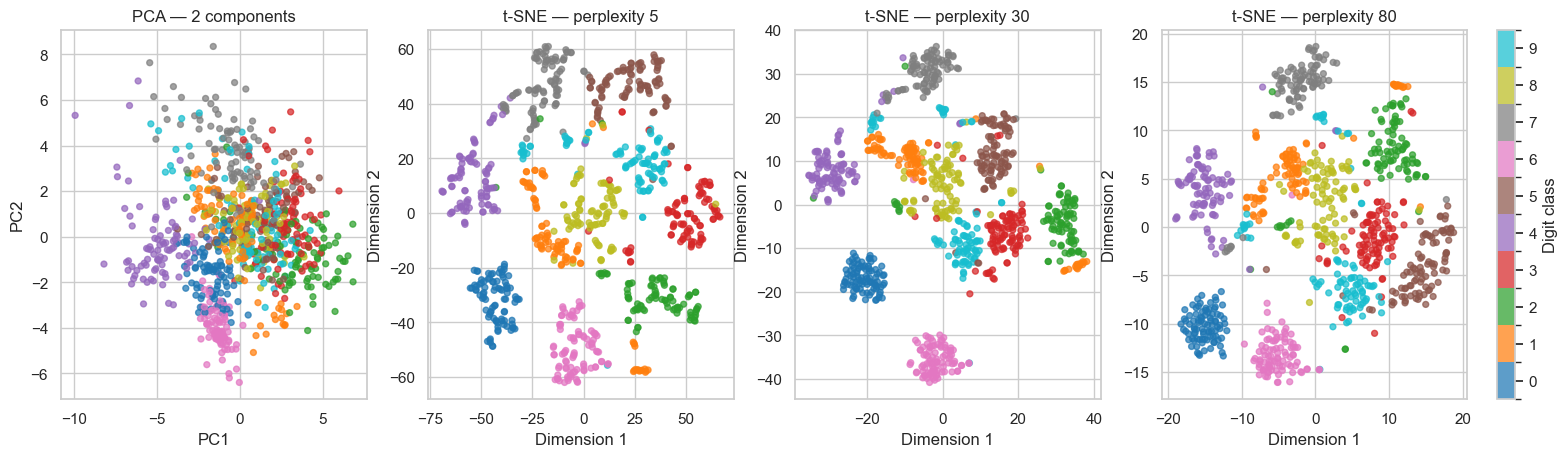

In [24]:
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm

fig, axes = plt.subplots(1, 4, figsize=(19, 4.8))

# Discrete colors for digit classes 0–9
cmap = plt.get_cmap('tab10')
norm = BoundaryNorm(
    boundaries=np.arange(-0.5, 10.5, 1),
    ncolors=10
)

scatter = axes[0].scatter(
    embedding_pca[:, 0], embedding_pca[:, 1],
    c=y_digits_view, cmap=cmap, norm=norm,
    s=18, alpha=0.72
)
axes[0].set_title('PCA — 2 components')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

for axis, perplexity in zip(axes[1:], PERPLEXITIES):
    embedding = embeddings_tsne[perplexity]
    axis.scatter(
        embedding[:, 0], embedding[:, 1],
        c=y_digits_view, cmap=cmap, norm=norm,
        s=18, alpha=0.72
    )
    axis.set_title(f't-SNE — perplexity {perplexity}')
    axis.set_xlabel('Dimension 1')
    axis.set_ylabel('Dimension 2')

# Shared colorbar
cbar = fig.colorbar(
    scatter,
    ax=axes,
    ticks=np.arange(10),
    fraction=0.025,
    pad=0.02
)
cbar.set_label('Digit class')

plt.show()

### Short Reading Stable patterns and misleading conclusions

When comparing t-SNE visualisations with different perplexity values, distinguish between **stable local patterns** and **unstable global arrangements**.

A pattern is more convincing if it appears across several reasonable parameter settings. For example, if observations from the same digit class repeatedly form a compact group, this suggests a consistent local similarity structure.

However, the following properties may change substantially:

- Distances between separated groups.
- Relative positions and orientations of groups.
- Apparent cluster sizes and shapes.
- Whether a group appears as one island or several smaller islands.

**A useful interpretation rule:**

- **Supported:** "These observations consistently appear close together across several settings."
- **Not supported:** "These two classes are three times more different because their islands are three times farther apart."

Remember that t-SNE is a visualisation method, not a proof that natural clusters exist in the original data.

A good scientific interpretation should describe what is visible, check whether the observation is stable, and avoid conclusions that the method cannot justify.

### Activity 6 - Separate observation from overclaim

Write one supported observation and one claim that would be too strong.

**Supported observation:**  

**Too-strong claim:**  

Then answer:

1. Which digit classes form stable local groups across settings?
2. Which relationships change substantially?
3. Why can two distant islands in t-SNE not automatically be interpreted as very dissimilar classes?

## Reading: Trustworthiness - Evaluating Neighbourhood Preservation

When using PCA or t-SNE to visualise high-dimensional data, we transform observations into a lower-dimensional space, usually 2D.

But how can we determine whether the resulting visualisation preserves meaningful relationships from the original data?

One useful metric is **trustworthiness**.

### 1. What does trustworthiness measure?

Trustworthiness evaluates how well the **local neighbourhoods in the low-dimensional representation agree with those in the original high-dimensional space**.

Imagine that we select an image of the digit 3.

In the original 64-dimensional space, its nearest neighbours might be other similarly written digits.

After applying t-SNE, we find its nearest neighbours again, this time in 2D.

Trustworthiness asks:

**Are the points that appear close together in 2D also close together in the original space?**

If the visualisation places originally distant observations close together, trustworthiness decreases.

### 2. How is trustworthiness calculated?

For each observation, we compare its $k$ nearest neighbours in the original space with its $k$ nearest neighbours in the reduced space.

The metric penalises **false neighbours** - observations that appear among the nearest neighbours in the reduced space but were not among the nearest neighbours in the original space.

The penalty is larger when a false neighbour was originally very distant.

The trustworthiness score is:

$$
T(k) = 1 -
\frac{2}{nk(2n-3k-1)}
\sum_{i=1}^{n}
\sum_{j\in U_i^{(k)}}
(r(i,j)-k)
$$

where:

- $n$ is the number of observations.
- $k$ is the number of nearest neighbours considered.
- $U_i^{(k)}$ contains the false neighbours of observation $i$ in the reduced space.
- $r(i,j)$ is the rank of observation $j$ among the neighbours of observation $i$ in the original space.

The result ranges from 0 to 1 for valid neighbourhood sizes.

- **Close to 1:** Local neighbourhoods are preserved well.
- **Lower values:** More originally distant observations appear as neighbours in the reduced space.

### 3. How to calculate trustworthiness in Python

Scikit-learn provides the function `trustworthiness`:

```python
from sklearn.manifold import trustworthiness

score = trustworthiness(
    X_digits_view,
    embedding_tsne,
    n_neighbors=10
)

print(f"Trustworthiness: {score:.3f}")
```

Here, `n_neighbors=10` means that we evaluate how well the ten nearest neighbours of each observation are preserved.

The score depends on the chosen neighbourhood size, so comparisons should use the same value of `n_neighbors`.

### 4. What does a high trustworthiness score NOT guarantee?

A high score does not mean that the entire visualisation is geometrically accurate.

In particular, trustworthiness does not guarantee that:

- Distances between distant groups are preserved.
- Cluster sizes and shapes are accurate.
- Visually separated groups correspond to real classes.
- The embedding is suitable for classification.

Trustworthiness also does not fully evaluate the opposite problem: original neighbours that become separated in the embedding. That aspect can be evaluated using a complementary measure called *continuity*.

**Remember:** Trustworthiness measures whether nearby points in the visualisation are genuinely nearby in the original data. It does not measure whether the entire geometric structure has been preserved.

### Audit local-neighbourhood preservation

`trustworthiness` asks whether points that appear close in the embedding were also reasonably close in the original feature space.

It is not a complete measure of embedding quality, but it provides evidence beyond visual appearance.

In [25]:
trust_rows = [{
    'representation': 'PCA — 2 components',
    'trustworthiness': trustworthiness(
        X_digits_view_scaled,
        embedding_pca,
        n_neighbors=10,
    ),
}]

for perplexity, embedding in embeddings_tsne.items():
    trust_rows.append({
        'representation': f't-SNE - perplexity {perplexity}',
        'trustworthiness': trustworthiness(
            X_digits_view_scaled,
            embedding,
            n_neighbors=10,
        ),
    })

trust_table = pd.DataFrame(trust_rows).sort_values('trustworthiness', ascending=False)
trust_table.round(3)

,representation,trustworthiness
2,t-SNE - perplexity 30,0.976
3,t-SNE - perplexity 80,0.973
1,t-SNE - perplexity 5,0.971
0,PCA — 2 components,0.823


### Verification checkpoint

1. Does the numerical audit agree with your visual impression?
2. Can a high trustworthiness score prove that all global distances are correct?
3. Why should several parameter settings be inspected rather than reporting one attractive t-SNE plot?

## 6. Optional UMAP comparison

UMAP is another non-linear embedding method. Two influential parameters are:

- `n_neighbors`: the local-versus-broader neighbourhood scale,
- `min_dist`: how tightly points may be packed in the embedding.

The next cell runs only when `umap-learn` is installed.

In Google Colab, install it once with:

```python
%pip install -q umap-learn
```

Then restart or rerun the import cell if necessary.

In [ ]:
try:
    import umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False
    print('UMAP is not installed. Run: %pip install -q umap-learn')

In [ ]:
UMAP_N_NEIGHBORS = 15
UMAP_MIN_DIST = 0.10

if UMAP_AVAILABLE:
    umap_model = umap.UMAP(
        n_components=2,
        n_neighbors=UMAP_N_NEIGHBORS,
        min_dist=UMAP_MIN_DIST,
        random_state=RANDOM_STATE,
    )
    embedding_umap = umap_model.fit_transform(X_digits_view_scaled)

    plt.figure(figsize=(7.5, 5.5))
    plt.scatter(embedding_umap[:, 0], embedding_umap[:, 1], c=y_digits_view, s=18, alpha=0.72)
    plt.title(
        f'UMAP — n_neighbors={UMAP_N_NEIGHBORS}, '
        f'min_dist={UMAP_MIN_DIST}'
    )
    plt.xlabel('Dimension 1')
    plt.ylabel('Dimension 2')
    plt.show()

    print(
        'Trustworthiness:',
        round(
            trustworthiness(
                X_digits_view_scaled,
                embedding_umap,
                n_neighbors=10,
            ),
            3,
        ),
    )
else:
    print('UMAP section skipped. PCA and t-SNE results remain available.')

### Optional interpretation

If UMAP ran, compare it with t-SNE:

- Which local groups appear stable in both methods?
- Which global relationships differ?
- What changes when `n_neighbors` is increased?
- Why should agreement between two methods increase confidence but still not prove a cluster structure?

## 7. Dimensionality reduction inside a modelling pipeline

When PCA is used before a supervised model, it must be fitted **inside** the training procedure.

Incorrect workflow:

1. fit PCA on the complete dataset,
2. cross-validate a classifier on the already transformed data.

Leakage-safe workflow:

1. each cross-validation fold fits scaling and PCA only on its training part,
2. the fitted transformation is applied to that fold's validation part.

A scikit-learn `Pipeline` enforces this sequence.

In [ ]:
X_wine_model = wine.data

y_wine_model = wine.target

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

baseline_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=3000)),
])

pca_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('pca', PCA(n_components=0.90)),
    ('classifier', LogisticRegression(max_iter=3000)),
])

baseline_scores = cross_validate(
    baseline_pipeline,
    X_wine_model,
    y_wine_model,
    cv=cv,
    scoring='accuracy',
    return_train_score=True,
)

pca_scores = cross_validate(
    pca_pipeline,
    X_wine_model,
    y_wine_model,
    cv=cv,
    scoring='accuracy',
    return_train_score=True,
)

pipeline_comparison = pd.DataFrame([
    {
        'pipeline': 'Scaled logistic regression',
        'mean train accuracy': baseline_scores['train_score'].mean(),
        'mean validation accuracy': baseline_scores['test_score'].mean(),
        'validation standard deviation': baseline_scores['test_score'].std(),
    },
    {
        'pipeline': 'Scaling + PCA(90%) + logistic regression',
        'mean train accuracy': pca_scores['train_score'].mean(),
        'mean validation accuracy': pca_scores['test_score'].mean(),
        'validation standard deviation': pca_scores['test_score'].std(),
    },
])

pipeline_comparison.round(3)

### Activity 7 - Interpret the modelling trade-off

1. Did PCA improve, preserve, or reduce validation accuracy?
2. Why might a lower-dimensional model still be useful even without higher accuracy?
3. Why is t-SNE not used in this pipeline?
4. What information would you need before claiming that PCA made the model “better”?

# End-of-lab self-check

Before finishing, check that you can:

- [ ] explain PC1 as a direction of maximum variance,
- [ ] explain why component signs may flip,
- [ ] distinguish projection from reconstruction,
- [ ] explain how scaling changes PCA,
- [ ] use cumulative explained variance without treating it as the only criterion,
- [ ] relate component count to visible reconstruction quality,
- [ ] explain why TruncatedSVD is useful for sparse matrices,
- [ ] distinguish PCA from t-SNE and UMAP,
- [ ] state which visual properties of t-SNE are unreliable,
- [ ] audit an embedding with another setting, method, or numerical measure,
- [ ] place PCA inside a leakage-safe pipeline,
- [ ] revise an embedding claim after evidence-based questions.

Exercise 9 will focus on systematic hyperparameter optimisation with Optuna.